<a href="https://colab.research.google.com/github/NafizHasanSinha/ATM-project/blob/main/Potato_Thesis_Notebook_with_Required_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import zipfile
import shutil
import hashlib
import random
import gc
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

In [ ]:
from google.colab import files

print("Please upload your NEW dataset ZIP file.")
uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))

print("\nUploaded file:", zip_name)

Please upload your NEW dataset ZIP file.


MessageError: TypeError: Cannot read properties of undefined (reading 'next')

In [ ]:
extract_dir = "/content/potato_dataset"

# Remove previous extraction if it exists
if os.path.exists(extract_dir):
    shutil.rmtree(extract_dir)

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted to:", extract_dir)

In [ ]:
print("\nTop-level folders/files:")

for item in sorted(os.listdir(extract_dir)):
    print(" -", item)

In [ ]:
def find_split_folder(root, possible_names):
    for current_root, dirs, files_ in os.walk(root):
        for d in dirs:
            if d.lower() in possible_names:
                return os.path.join(current_root, d)
    return None


train_dir = find_split_folder(
    extract_dir,
    {"train", "training"}
)

val_dir = find_split_folder(
    extract_dir,
    {"val", "valid", "validation"}
)

test_dir = find_split_folder(
    extract_dir,
    {"test", "testing"}
)

print("\nDetected dataset splits:")
print("Train      :", train_dir)
print("Validation :", val_dir)
print("Test       :", test_dir)

In [ ]:
if train_dir is not None:
    classes = sorted([
        d for d in os.listdir(train_dir)
        if os.path.isdir(os.path.join(train_dir, d))
    ])
else:
    classes = []

print("\nDetected classes:")
for i, cls in enumerate(classes):
    print(f"{i}: {cls}")

**Count images in each split**

In [ ]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

def get_image_files(folder):
    if folder is None:
        return []

    image_files = []

    for root, dirs, files_ in os.walk(folder):
        for file in files_:
            if Path(file).suffix.lower() in IMAGE_EXTENSIONS:
                image_files.append(os.path.join(root, file))

    return sorted(image_files)


def count_by_class(split_dir, classes):
    result = {}

    if split_dir is None:
        return result

    for cls in classes:
        class_dir = os.path.join(split_dir, cls)

        if os.path.isdir(class_dir):
            files_ = get_image_files(class_dir)
            result[cls] = len(files_)
        else:
            result[cls] = 0

    return result


train_counts = count_by_class(train_dir, classes)
val_counts = count_by_class(val_dir, classes)
test_counts = count_by_class(test_dir, classes)

distribution_df = pd.DataFrame({
    "Class": classes,
    "Train": [train_counts.get(c, 0) for c in classes],
    "Validation": [val_counts.get(c, 0) for c in classes],
    "Test": [test_counts.get(c, 0) for c in classes]
})

distribution_df["Total"] = (
    distribution_df["Train"]
    + distribution_df["Validation"]
    + distribution_df["Test"]
)

print("\n================ DATASET DISTRIBUTION ================\n")
print(distribution_df.to_string(index=False))

print("\nTotal images:")
print("Train      :", distribution_df["Train"].sum())
print("Validation :", distribution_df["Validation"].sum())
print("Test       :", distribution_df["Test"].sum())
print("TOTAL      :", distribution_df["Total"].sum())


**image dimensions**

In [ ]:
print("\n================ IMAGE DIMENSIONS ================\n")

all_images = []

for split_name, split_dir in [
    ("Train", train_dir),
    ("Validation", val_dir),
    ("Test", test_dir)
]:
    files_ = get_image_files(split_dir)

    for file in files_:
        all_images.append((split_name, file))

dimension_counter = Counter()
corrupted_images = []

for split_name, file in all_images:

    try:
        with Image.open(file) as img:
            dimension_counter[img.size] += 1

    except Exception as e:
        corrupted_images.append({
            "split": split_name,
            "file": file,
            "error": str(e)
        })

print("Most common image dimensions:")

for size, count in dimension_counter.most_common(10):
    print(f"{size}: {count} images")

print("\nCorrupted/unreadable images:", len(corrupted_images))

DUPLICATE CHECK

In [ ]:
print("\n================ DUPLICATE CHECK =================\n")

def file_hash(filepath):
    md5 = hashlib.md5()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            md5.update(chunk)
    return md5.hexdigest()

hash_records = []
for split_name, file in all_images:
    try:
        file_hash_value = file_hash(file)
        hash_records.append({
            "split": split_name,
            "file": file,
            "hash": file_hash_value
        })
    except Exception:
        pass

hash_df = pd.DataFrame(hash_records)
duplicate_groups = (
    hash_df.groupby("hash")
    .filter(lambda x: len(x) > 1)
)

print("Total image files checked:", len(hash_df))
print("Unique image contents    :", hash_df["hash"].nunique())
print("Duplicate image files   :", len(duplicate_groups))

CROSS-SPLIT duplicates

In [ ]:
cross_split_duplicates = []

if not hash_df.empty:

    for hash_value, group in hash_df.groupby("hash"):

        splits_present = set(group["split"])

        if len(splits_present) > 1:

            cross_split_duplicates.append(group)

if cross_split_duplicates:

    cross_split_df = pd.concat(cross_split_duplicates)

    print(
        "\nWARNING:",
        len(cross_split_df),
        "files belong to duplicate groups appearing across different splits."
    )

    print("\nExamples:")

    print(
        cross_split_df[
            ["split", "file", "hash"]
        ].head(20).to_string(index=False)
    )

else:

    print("\nGOOD: No exact duplicate image found across Train/Validation/Test.")


In [ ]:
print("                 DATASET AUDIT SUMMARY")

print("Classes:", classes)

print("Total images:", len(all_images))

print("Corrupted images:", len(corrupted_images))

print(
    "Cross-split duplicate groups:",
    len(cross_split_duplicates)
)



In [ ]:
# Removed duplicate imports (os, shutil, hashlib, Path are already imported at the top)

In [ ]:
SOURCE_DIR = "/content/potato_dataset/PLD_3_Classes_256"
CLEAN_DIR = "/content/PLD_Clean"

 Remove previous clean dataset if it exists

In [ ]:

if os.path.exists(CLEAN_DIR):
    shutil.rmtree(CLEAN_DIR)

os.makedirs(CLEAN_DIR, exist_ok=True)


 Helper functions


In [ ]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

def get_images(folder):
    image_files = []

    for root, dirs, files in os.walk(folder):
        for file in files:
            if Path(file).suffix.lower() in IMAGE_EXTENSIONS:
                image_files.append(os.path.join(root, file))

    return sorted(image_files)


def image_hash(filepath):
    md5 = hashlib.md5()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            md5.update(chunk)

    return md5.hexdigest()


Build hash maps for Train / Validation / Test

In [ ]:
splits = {
    "Training": "Training",
    "Validation": "Validation",
    "Testing": "Testing"
}

hash_map = {}

for split_name, split_folder in splits.items():

    split_path = os.path.join(SOURCE_DIR, split_folder)

    for file in get_images(split_path):

        h = image_hash(file)

        hash_map.setdefault(h, []).append({
            "split": split_name,
            "file": file
        })



**Identify cross-split duplicates**

In [ ]:
cross_split_groups = []

for h, records in hash_map.items():

    split_names = set(record["split"] for record in records)

    if len(split_names) > 1:
        cross_split_groups.append(records)


print("Cross-split duplicate groups found:",
      len(cross_split_groups))



In [ ]:
exclude_from_test = set()

for group in cross_split_groups:

    # Keep Training copy.
    # Remove duplicate copy from Test.
    for record in group:

        if record["split"] == "Testing":
            exclude_from_test.add(record["file"])


print("Test images excluded due to leakage:",
      len(exclude_from_test))



In [ ]:
copied_count = 0
excluded_count = 0

for split_name, split_folder in splits.items():

    source_split = os.path.join(SOURCE_DIR, split_folder)
    clean_split = os.path.join(CLEAN_DIR, split_folder)

    os.makedirs(clean_split, exist_ok=True)

    for class_name in sorted(os.listdir(source_split)):

        source_class = os.path.join(
            source_split,
            class_name
        )

        if not os.path.isdir(source_class):
            continue

        clean_class = os.path.join(
            clean_split,
            class_name
        )

        os.makedirs(clean_class, exist_ok=True)

        for file in get_images(source_class):

            # Skip only duplicated Test copies
            if file in exclude_from_test:
                excluded_count += 1
                continue

            destination = os.path.join(
                clean_class,
                os.path.basename(file)
            )

            shutil.copy2(file, destination)

            copied_count += 1


In [ ]:

print("CLEAN DATASET CREATED")
print("==============================================")

print("Original dataset :", SOURCE_DIR)
print("Clean dataset    :", CLEAN_DIR)

print("\nImages copied :", copied_count)
print("Images removed:", excluded_count)

print("CLEAN DATASET DISTRIBUTION")
print("==============================================")


for split_name, split_folder in splits.items():

    split_path = os.path.join(
        CLEAN_DIR,
        split_folder
    )

    total = 0

    print(f"\n{split_name}:")

    for class_name in sorted(os.listdir(split_path)):

        class_path = os.path.join(
            split_path,
            class_name
        )

        if not os.path.isdir(class_path):
            continue

        count = len(get_images(class_path))
        total += count

        print(f"  {class_name}: {count}")

    print(f"  Total: {total}")


print("Original dataset remains untouched.")
print("==============================================")

**Visual Inspection of Clean Dataset**

In [ ]:


CLEAN_DIR = "/content/PLD_Clean"

classes = [
    "Early_Blight",
    "Healthy",
    "Late_Blight"
]

splits = [
    "Training",
    "Validation",
    "Testing"
]

plt.figure(figsize=(15, 10))

plot_index = 1

for class_name in classes:

    class_path = os.path.join(
        CLEAN_DIR,
        "Training",
        class_name
    )

    image_files = [
        os.path.join(class_path, f)
        for f in os.listdir(class_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    samples = random.sample(
        image_files,
        min(4, len(image_files))
    )

    for image_path in samples:

        image = Image.open(image_path)

        plt.subplot(3, 4, plot_index)
        plt.imshow(image)
        plt.title(class_name.replace("_", " "))
        plt.axis("off")

        plot_index += 1

plt.suptitle(
    "Sample Images from Clean Training Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

**TensorFlow Dataset Pipeline + Data Augmentation**

In [ ]:

# Dataset path
CLEAN_DIR = "/content/PLD_Clean"

# Image settings
IMG_SIZE = (256, 256)
BATCH_SIZE = 32
SEED = 42

# Class names
CLASS_NAMES = [
    "Early_Blight",
    "Healthy",
    "Late_Blight"
]

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(CLEAN_DIR, "Training"),
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)


val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(CLEAN_DIR, "Validation"),
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)


test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(CLEAN_DIR, "Testing"),
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)


Data Augmentation

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        "horizontal"
    ),

    tf.keras.layers.RandomRotation(
        0.08
    ),

    tf.keras.layers.RandomZoom(
        0.10
    ),

    tf.keras.layers.RandomContrast(
        0.10
    )
], name="data_augmentation")

# Performance optimization

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [ ]:
print("             DATASET PIPELINE READY")

print("Image size :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)

print("\nClasses:")
for i, name in enumerate(CLASS_NAMES):
    print(f"{i}: {name}")

print("\nTraining batches  :", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches   :", tf.data.experimental.cardinality(test_ds).numpy())

print("\nAugmentation:")
print("- Random Horizontal Flip")
print("- Random Rotation")
print("- Random Zoom")
print("- Random Contrast")

print("\nValidation/Test augmentation: DISABLED")

**Custom CNN Baseline Model**

In [31]:
from tensorflow.keras import layers, regularizers, models

baseline_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.08),
], name="baseline_augmentation")


def build_baseline_cnn():
    inputs = layers.Input(shape=(256, 256, 3), name="image_input")

    x = layers.Rescaling(1.0 / 255.0, name="rescaling")(inputs)
    x = baseline_augmentation(x)

    # Block 1
    x = layers.Conv2D(32, 3, padding="same", use_bias=False,
                      kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.20)(x)

    # Block 2
    x = layers.Conv2D(64, 3, padding="same", use_bias=False,
                      kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)

    # Block 3
    x = layers.Conv2D(128, 3, padding="same", use_bias=False,
                      kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.30)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu",
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(3, activation="softmax", name="class_output")(x)

    return models.Model(inputs, outputs, name="Regularized_Baseline_CNN")


baseline_cnn = build_baseline_cnn()


In [33]:
baseline_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [34]:
baseline_cnn.summary()

Model: "Regularized_Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_augmentation           │ (None, 256, 256, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 256, 256, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 64, 64, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_output (Dense)            │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 102,371 (399.89 KB)

 Trainable params: 101,923 (398.14 KB)

 Non-trainable params: 448 (1.75 KB)

In [35]:
# Use smaller batch size for safer training

BATCH_SIZE_BASELINE = 16

train_baseline = tf.keras.utils.image_dataset_from_directory(
    "/content/PLD_Clean/Training",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(256, 256),
    batch_size=BATCH_SIZE_BASELINE,
    shuffle=True,
    seed=42
)

val_baseline = tf.keras.utils.image_dataset_from_directory(
    "/content/PLD_Clean/Validation",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(256, 256),
    batch_size=BATCH_SIZE_BASELINE,
    shuffle=False
)

Found 3251 files belonging to 3 classes.
Found 416 files belonging to 3 classes.


In [36]:
# Performance optimization

AUTOTUNE = tf.data.AUTOTUNE

train_baseline = train_baseline.prefetch(AUTOTUNE)
val_baseline = val_baseline.prefetch(AUTOTUNE)



baseline_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]



**Train**

In [37]:
print("                TRAINING BASELINE CUSTOM CNN")

baseline_history = baseline_cnn.fit(
    train_baseline,
    validation_data=val_baseline,
    epochs=20,
    callbacks=baseline_callbacks,
    verbose=1
)

print("                   BASELINE TRAINING COMPLETED")

print(
    "Best Validation Accuracy:",
    max(baseline_history.history["val_accuracy"])
)

print(
    "Best Validation Loss:",
    min(baseline_history.history["val_loss"])
)

                TRAINING BASELINE CUSTOM CNN
Epoch 1/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - accuracy: 0.6041 - loss: 0.9259 - val_accuracy: 0.4423 - val_loss: 1.6005 - learning_rate: 0.0010
Epoch 2/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 24s 116ms/step - accuracy: 0.6927 - loss: 0.7826 - val_accuracy: 0.5337 - val_loss: 1.5108 - learning_rate: 0.0010
Epoch 3/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - accuracy: 0.7133 - loss: 0.7241 - val_accuracy: 0.5962 - val_loss: 0.8474 - learning_rate: 0.0010
Epoch 4/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - accuracy: 0.7407 - loss: 0.6804 - val_accuracy: 0.3269 - val_loss: 1.3361 - learning_rate: 0.0010
Epoch 5/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - accuracy: 0.7573 - loss: 0.6404 - val_accuracy: 0.4471 - val_loss: 1.2665 - learning_rate: 0.0010
Epoch 6/20
203/204 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.7658 - loss: 0.6539
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
204/204 ━━━━━━━

In [38]:

# Improved Custom CNN

def build_improved_cnn():

    inputs = layers.Input(
        shape=(256, 256, 3)
    )

    x = data_augmentation(inputs)

    x = layers.Conv2D(
        32,
        (3, 3),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        32,
        (3, 3),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)

    x = layers.Dropout(0.15)(x)

    # Block 2


    x = layers.Conv2D(
        64,
        (3, 3),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        64,
        (3, 3),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)

    x = layers.Dropout(0.20)(x)

    # Block 3

    x = layers.Conv2D(
        128,
        (3, 3),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        128,
        (3, 3),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)

    x = layers.Dropout(0.25)(x)

    # Block 4

    x = layers.Conv2D(
        256,
        (3, 3),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # Global Average Pooling

    x = layers.GlobalAveragePooling2D()(x)

    # Dense layer with L2 regularization

    x = layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.Dropout(0.35)(x)


    outputs = layers.Dense(
        3,
        activation="softmax"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="Improved_Custom_CNN"
    )

    return model


improved_cnn = build_improved_cnn()

# Compile

improved_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)



improved_cnn.summary()

Model: "Improved_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 256, 256, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 256, 256, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 128, 128, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 128, 128, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 64, 64, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 64, 64, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 617,571 (2.36 MB)

 Trainable params: 616,163 (2.35 MB)

 Non-trainable params: 1,408 (5.50 KB)

**Train Improved Custom CNN**

In [39]:
BATCH_SIZE_IMPROVED = 16

train_improved = tf.keras.utils.image_dataset_from_directory(
    "/content/PLD_Clean/Training",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(256, 256),
    batch_size=BATCH_SIZE_IMPROVED,
    shuffle=True,
    seed=42
)


val_improved = tf.keras.utils.image_dataset_from_directory(
    "/content/PLD_Clean/Validation",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(256, 256),
    batch_size=BATCH_SIZE_IMPROVED,
    shuffle=False
)
AUTOTUNE = tf.data.AUTOTUNE

train_improved = train_improved.prefetch(AUTOTUNE)
val_improved = val_improved.prefetch(AUTOTUNE)


improved_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]



print("TRAINING IMPROVED CUSTOM CNN")

improved_history = improved_cnn.fit(
    train_improved,
    validation_data=val_improved,
    epochs=20,
    callbacks=improved_callbacks,
    verbose=1
)

print("IMPROVED TRAINING COMPLETED")

print(
    "Best Validation Accuracy:",
    max(improved_history.history["val_accuracy"])
)

print(
    "Best Validation Loss:",
    min(improved_history.history["val_loss"])
)

Found 3251 files belonging to 3 classes.
Found 416 files belonging to 3 classes.
TRAINING IMPROVED CUSTOM CNN
Epoch 1/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 66s 245ms/step - accuracy: 0.6798 - loss: 0.7679 - val_accuracy: 0.3678 - val_loss: 3.7024 - learning_rate: 0.0010
Epoch 2/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 48s 235ms/step - accuracy: 0.7770 - loss: 0.5948 - val_accuracy: 0.5288 - val_loss: 1.3471 - learning_rate: 0.0010
Epoch 3/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 83s 241ms/step - accuracy: 0.8142 - loss: 0.5115 - val_accuracy: 0.7356 - val_loss: 0.7040 - learning_rate: 0.0010
Epoch 4/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 48s 233ms/step - accuracy: 0.8785 - loss: 0.3454 - val_accuracy: 0.4784 - val_loss: 1.3459 - learning_rate: 0.0010
Epoch 5/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 48s 236ms/step - accuracy: 0.8917 - loss: 0.3237 - val_accuracy: 0.8630 - val_loss: 0.4089 - learning_rate: 0.0010
Epoch 6/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 47s 231ms/step - accuracy: 0.9120 - loss: 0.2737 - val_accuracy: 0.4736 - v

Load Clean Test Dataset

In [40]:

test_final = tf.keras.utils.image_dataset_from_directory(
    "/content/PLD_Clean/Testing",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(256, 256),
    batch_size=16,
    shuffle=False
)


test_final = test_final.prefetch(
    tf.data.AUTOTUNE
)




print("            FINAL TEST EVALUATION")

test_loss, test_accuracy = improved_cnn.evaluate(
    test_final,
    verbose=1
)

print("             FINAL TEST RESULT")

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : {test_accuracy:.4f}"
)

print(
    f"Test Accuracy : {test_accuracy * 100:.2f}%"
)

Found 402 files belonging to 3 classes.
            FINAL TEST EVALUATION
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.9428 - loss: 0.1566
             FINAL TEST RESULT
Test Loss     : 0.1566
Test Accuracy : 0.9428
Test Accuracy : 94.28%


 Classification Report & Confusion Matrix

In [41]:
y_true = []
y_pred = []

for images, labels in test_final:
    predictions = improved_cnn.predict(
        images,
        verbose=0
    )
    predicted_classes = np.argmax(
        predictions,
        axis=1
    )
    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("CLASSIFICATION REPORT")
report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
)
print(report)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

Early_Blight     1.0000    0.8696    0.9302       161
     Healthy     0.8850    1.0000    0.9390       100
 Late_Blight     0.9329    0.9858    0.9586       141

    accuracy                         0.9428       402
   macro avg     0.9393    0.9518    0.9426       402
weighted avg     0.9478    0.9428    0.9424       402



In [42]:
cm = confusion_matrix(
    y_true,
    y_pred
)
print("CONFUSION MATRIX")

print(cm)



CONFUSION MATRIX
[[140  11  10]
 [  0 100   0]
 [  0   2 139]]


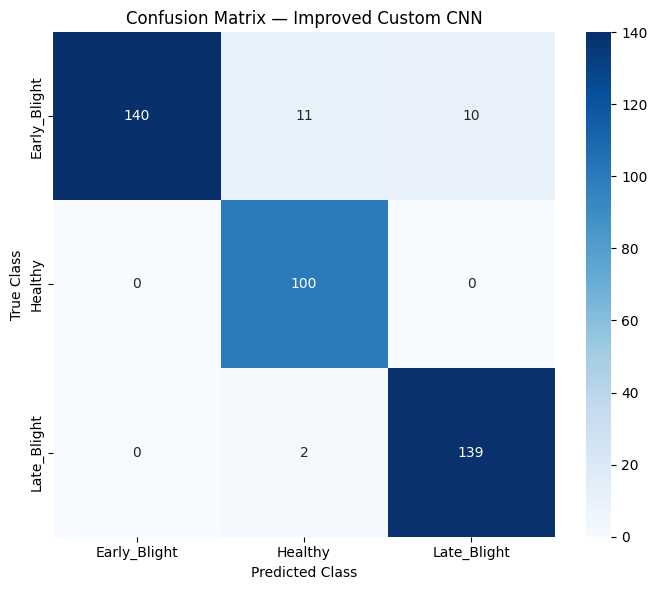

In [43]:
# Plot Confusion Matrix

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix — Improved Custom CNN")

plt.tight_layout()
plt.show()

Training & Validation Curves

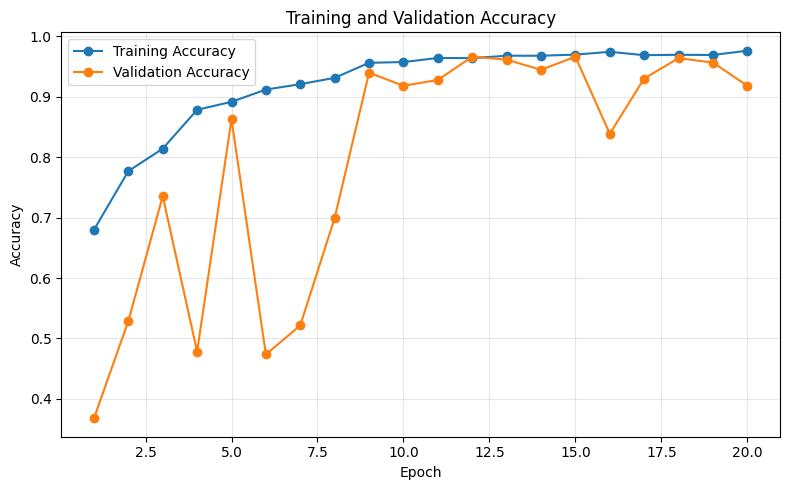

In [44]:
history = improved_history.history

epochs_range = range(
    1,
    len(history["accuracy"]) + 1
)
# Accuracy Curve


plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()




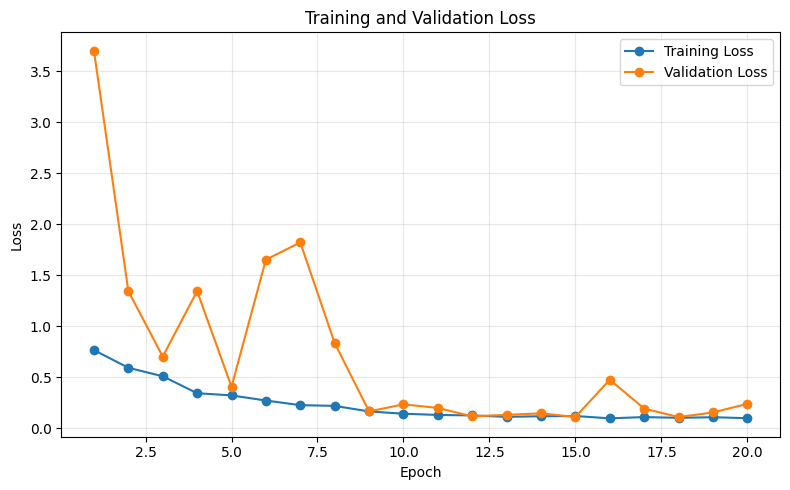

In [45]:
#Loss Curve


plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Baseline vs Improved CNN Test Comparison

In [46]:
# Evaluate Baseline CNN
baseline_test_loss, baseline_test_accuracy = baseline_cnn.evaluate(
    test_final,
    verbose=0
)

# Improved CNN result

improved_test_loss, improved_test_accuracy = improved_cnn.evaluate(
    test_final,
    verbose=0
)

# Comparison table

comparison = pd.DataFrame({
    "Model": [
        "Baseline Custom CNN",
        "Improved Custom CNN"
    ],

    "Validation Accuracy (%)": [
        max(baseline_history.history["val_accuracy"]) * 100,
        max(improved_history.history["val_accuracy"]) * 100
    ],

    "Test Accuracy (%)": [
        baseline_test_accuracy * 100,
        improved_test_accuracy * 100
    ],

    "Test Loss": [
        baseline_test_loss,
        improved_test_loss
    ]
})

print("        BASELINE vs IMPROVED CNN")

display(
    comparison.round(4)
)

# Improvement

accuracy_improvement = (
    improved_test_accuracy - baseline_test_accuracy
) * 100

print("         IMPROVEMENT")

print(
    f"Test Accuracy Improvement: "
    f"{accuracy_improvement:.2f} percentage points"
)

        BASELINE vs IMPROVED CNN


,Model,Validation Accuracy (%),Test Accuracy (%),Test Loss
0,Baseline Custom CNN,59.6154,63.6816,0.7775
1,Improved Custom CNN,96.6346,94.2786,0.1566


         IMPROVEMENT
Test Accuracy Improvement: 30.60 percentage points


In [47]:
import gc

IMG_SIZE = (256, 256)
BATCH_SIZE = 16
EPOCHS = 20

CLEAN_DIR = "/content/PLD_Clean"

train_compare = tf.keras.utils.image_dataset_from_directory(
    f"{CLEAN_DIR}/Training",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_compare = tf.keras.utils.image_dataset_from_directory(
    f"{CLEAN_DIR}/Validation",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_compare = tf.keras.utils.image_dataset_from_directory(
    f"{CLEAN_DIR}/Testing",
    labels="inferred",
    label_mode="int",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE

train_compare = train_compare.prefetch(AUTOTUNE)
val_compare = val_compare.prefetch(AUTOTUNE)
test_compare = test_compare.prefetch(AUTOTUNE)


# Common AUGMENTATION

comparison_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
])


# CALLBACK FUNCTION

def get_callbacks(model_name):

    return [

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-6,
            verbose=1
        )
    ]


results = []


# FUNCTION FOR TRAINING + EVALUATION

def train_and_evaluate(
    model,
    model_name
):

    print("\n")
    print("=" * 60)
    print(f"TRAINING {model_name}")
    print("=" * 60)

    history = model.fit(
        train_compare,
        validation_data=val_compare,
        epochs=EPOCHS,
        callbacks=get_callbacks(model_name),
        verbose=1
    )

    # Best validation accuracy

    best_val_accuracy = max(
        history.history["val_accuracy"]
    )

    best_val_loss = min(
        history.history["val_loss"]
    )

    # Test evaluation

    test_loss, test_accuracy = model.evaluate(
        test_compare,
        verbose=1
    )

    print("\n" + "-" * 60)
    print(f"{model_name} RESULT")
    print("-" * 60)

    print(
        f"Best Validation Accuracy: "
        f"{best_val_accuracy * 100:.2f}%"
    )

    print(
        f"Best Validation Loss: "
        f"{best_val_loss:.4f}"
    )

    print(
        f"Test Accuracy: "
        f"{test_accuracy * 100:.2f}%"
    )

    print(
        f"Test Loss: "
        f"{test_loss:.4f}"
    )

    results.append({
        "Model": model_name,
        "Validation Accuracy (%)":
            best_val_accuracy * 100,
        "Test Accuracy (%)":
            test_accuracy * 100,
        "Test Loss":
            test_loss
    })

    return history


#  RESNET50

print("\n")
print("# 1/3 — RESNET50")

resnet_base = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(256, 256, 3)
)

resnet_base.trainable = False

inputs = layers.Input(
    shape=(256, 256, 3)
)

x = comparison_augmentation(inputs)

x = tf.keras.applications.resnet50.preprocess_input(x)

x = resnet_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

resnet_model = models.Model(
    inputs,
    outputs,
    name="ResNet50"
)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_history = train_and_evaluate(
    resnet_model,
    "ResNet50"
)

# Clear memory
del resnet_model
del resnet_base
gc.collect()
tf.keras.backend.clear_session()


# 2. MOBILENETV2

print("\n")
print("# 2/3 — MOBILENETV2")

mobilenet_base = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(256, 256, 3)
)

mobilenet_base.trainable = False

inputs = layers.Input(
    shape=(256, 256, 3)
)

x = comparison_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = mobilenet_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

mobilenet_model = models.Model(
    inputs,
    outputs,
    name="MobileNetV2"
)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_history = train_and_evaluate(
    mobilenet_model,
    "MobileNetV2"
)

# Clear memory
del mobilenet_model
del mobilenet_base
gc.collect()
tf.keras.backend.clear_session()


# 3. EFFICIENTNETB0

print("\n")
print("# 3/3 — EFFICIENTNETB0")

efficientnet_base = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(256, 256, 3)
)

efficientnet_base.trainable = False

inputs = layers.Input(
    shape=(256, 256, 3)
)

x = comparison_augmentation(inputs)

x = efficientnet_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

efficientnet_model = models.Model(
    inputs,
    outputs,
    name="EfficientNetB0"
)

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_history = train_and_evaluate(
    efficientnet_model,
    "EfficientNetB0"
)


# FINAL COMPARISON TABLE

comparison_results = pd.DataFrame(results)

print("\n")
print("=" * 70)
print("FINAL COMPARISON — PRETRAINED MODELS")
print("=" * 70)

display(
    comparison_results.round(4)
)

Found 3251 files belonging to 3 classes.
Found 416 files belonging to 3 classes.
Found 402 files belonging to 3 classes.


# 1/3 — RESNET50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


TRAINING ResNet50
Epoch 1/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 34s 133ms/step - accuracy: 0.8720 - loss: 0.3354 - val_accuracy: 0.9760 - val_loss: 0.1154 - learning_rate: 0.0010
Epoch 2/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 24s 119ms/step - accuracy: 0.9502 - loss: 0.1465 - val_accuracy: 0.9736 - val_loss: 0.0860 - learning_rate: 0.0010
Epoch 3/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 23s 114ms/step - accuracy: 0.9637 - loss: 0.1103 - val_accuracy: 0.9856 - val_loss: 0.0699 - learning_rate: 0.0010
Epoch 4/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 41s 116ms/step - accuracy: 0.9689 - loss: 0.0952 - val_accuracy: 0.9904 - val_loss: 0.0666 - learning_rate: 0.0010
Epoch 5/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 25s 122ms/step - accuracy: 0.9745 - loss: 0.0855 - val_accuracy: 0.9880 - val_loss: 0.0603 - learning_rate: 0.0010
Epoch 6/20
204

/tmp/ipykernel_1646/2259775155.py:222: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet_base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


TRAINING MobileNetV2
Epoch 1/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 17s 59ms/step - accuracy: 0.8425 - loss: 0.4077 - val_accuracy: 0.9351 - val_loss: 0.1945 - learning_rate: 0.0010
Epoch 2/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.9293 - loss: 0.2046 - val_accuracy: 0.9231 - val_loss: 0.1887 - learning_rate: 0.0010
Epoch 3/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.9412 - loss: 0.1668 - val_accuracy: 0.9447 - val_loss: 0.1504 - learning_rate: 0.0010
Epoch 4/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.9416 - loss: 0.1594 - val_accuracy: 0.9423 - val_loss: 0.1441 - learning_rate: 0.0010
Epoch 5/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.9514 - loss: 0.1521 - val_accuracy: 0.9471 - val_loss: 0.1430 - learning_rate: 0.0010
Epoch 6/20
204/204 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.9554 - loss: 0.1282 - val_accuracy: 0.9447 - val_loss: 0.1452 - learning_rate: 0.0010
Epoc

,Model,Validation Accuracy (%),Test Accuracy (%),Test Loss
0,ResNet50,99.0385,99.0050,0.0378
1,MobileNetV2,97.5962,98.5075,0.0969
2,EfficientNetB0,98.0769,97.7612,0.0762


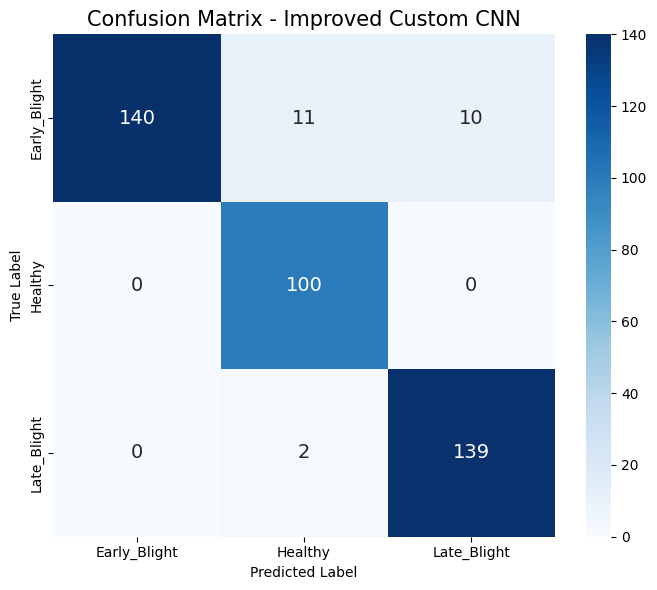

Classification Report:
              precision    recall  f1-score   support

Early_Blight     1.0000    0.8696    0.9302       161
     Healthy     0.8850    1.0000    0.9390       100
 Late_Blight     0.9329    0.9858    0.9586       141

    accuracy                         0.9428       402
   macro avg     0.9393    0.9518    0.9426       402
weighted avg     0.9478    0.9428    0.9424       402



In [48]:
y_true = []
y_pred = []

for images, labels in test_final:
    predictions = improved_cnn.predict(images, verbose=0)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

class_names = ["Early_Blight", "Healthy", "Late_Blight"]

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 14}
)

plt.title("Confusion Matrix - Improved Custom CNN", fontsize=15)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

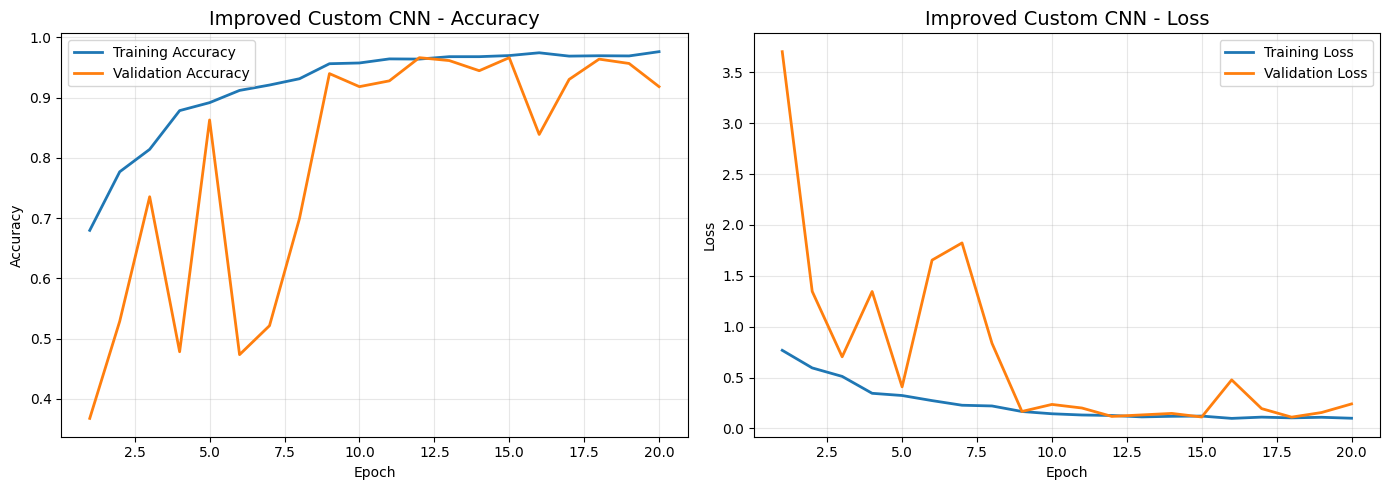

In [49]:
# Training history
history = improved_history.history

epochs = range(1, len(history["accuracy"]) + 1)

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs, history["accuracy"], label="Training Accuracy", linewidth=2)
plt.plot(epochs, history["val_accuracy"], label="Validation Accuracy", linewidth=2)
plt.title("Improved Custom CNN - Accuracy", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs, history["loss"], label="Training Loss", linewidth=2)
plt.plot(epochs, history["val_loss"], label="Validation Loss", linewidth=2)
plt.title("Improved Custom CNN - Loss", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

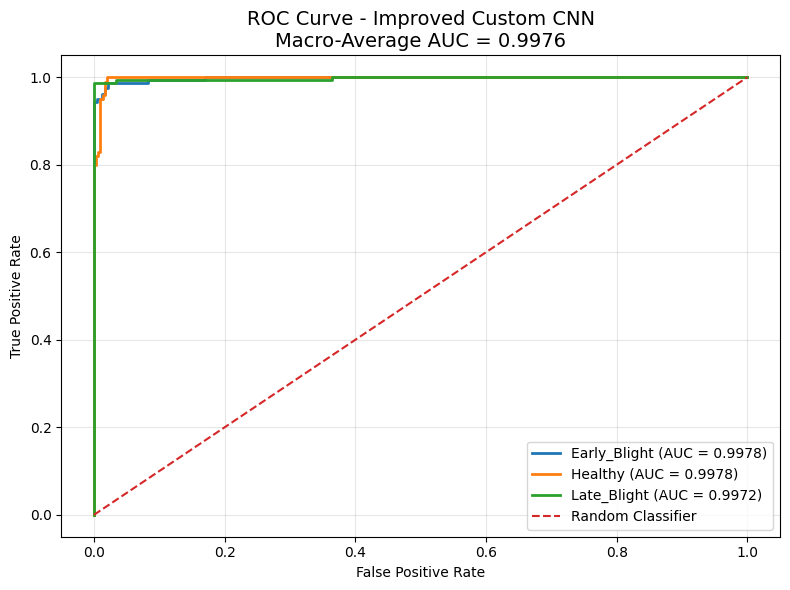

Class-wise AUC:
Early_Blight: 0.9978
Healthy: 0.9978
Late_Blight: 0.9972

Macro-Average AUC: 0.9976


In [50]:
class_names = ["Early_Blight", "Healthy", "Late_Blight"]

# Get true labels and prediction probabilities
y_true = []
y_prob = []

for images, labels in test_final:
    probabilities = improved_cnn.predict(images, verbose=0)
    y_prob.extend(probabilities)
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# Convert labels to one-vs-rest format
y_true_bin = label_binarize(
    y_true,
    classes=[0, 1, 2]
)

# Calculate ROC curve and AUC for each class
fpr = {}
tpr = {}
roc_auc = {}

for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )
    roc_auc[i] = auc(fpr[i], tpr[i])

# Macro-average AUC
macro_auc = roc_auc_score(
    y_true_bin,
    y_prob,
    multi_class="ovr",
    average="macro"
)

# Plot ROC curves
plt.figure(figsize=(8, 6))
for i in range(3):
    plt.plot(
        fpr[i],
        tpr[i],
        linewidth=2,
        label=f"{class_names[i]} (AUC = {roc_auc[i]:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    f"ROC Curve - Improved Custom CNN\nMacro-Average AUC = {macro_auc:.4f}",
    fontsize=14
)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Class-wise AUC:")
for i in range(3):
    print(f"{class_names[i]}: {roc_auc[i]:.4f}")

print(f"\nMacro-Average AUC: {macro_auc:.4f}")

In [51]:
# ResNet50 backbone
resnet_base = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(256, 256, 3)
)

# Freeze pretrained layers
resnet_base.trainable = False

# Build ResNet50 model
resnet_model = models.Sequential([
    layers.Input(shape=(256, 256, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),

    resnet_base,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(3, activation="softmax")
])

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 256, 256, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [52]:
# Save the best ResNet50 weights
resnet_checkpoint = "/content/resnet50_best.weights.h5"

callbacks = [
    ModelCheckpoint(
        resnet_checkpoint,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Train ResNet50
resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

# Load the best saved weights
resnet_model.load_weights(resnet_checkpoint)

# Final test evaluation
resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    test_ds,
    verbose=1
)

print("\nResNet50 Final Test Results")
print(f"Test Loss     : {resnet_test_loss:.4f}")
print(f"Test Accuracy : {resnet_test_accuracy * 100:.2f}%")

Epoch 1/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.7071 - loss: 0.6444
Epoch 1: val_accuracy improved from None to 0.93510, saving model to /content/resnet50_best.weights.h5

Epoch 1: finished saving model to /content/resnet50_best.weights.h5
102/102 ━━━━━━━━━━━━━━━━━━━━ 34s 252ms/step - accuracy: 0.8222 - loss: 0.4284 - val_accuracy: 0.9351 - val_loss: 0.2057 - learning_rate: 0.0010
Epoch 2/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.8993 - loss: 0.2556
Epoch 2: val_accuracy improved from 0.93510 to 0.93750, saving model to /content/resnet50_best.weights.h5

Epoch 2: finished saving model to /content/resnet50_best.weights.h5
102/102 ━━━━━━━━━━━━━━━━━━━━ 24s 234ms/step - accuracy: 0.9117 - loss: 0.2360 - val_accuracy: 0.9375 - val_loss: 0.1682 - learning_rate: 0.0010
Epoch 3/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step - accuracy: 0.9378 - loss: 0.1814
Epoch 3: val_accuracy improved from 0.93750 to 0.94952, saving model to /content/resnet50_best.weight

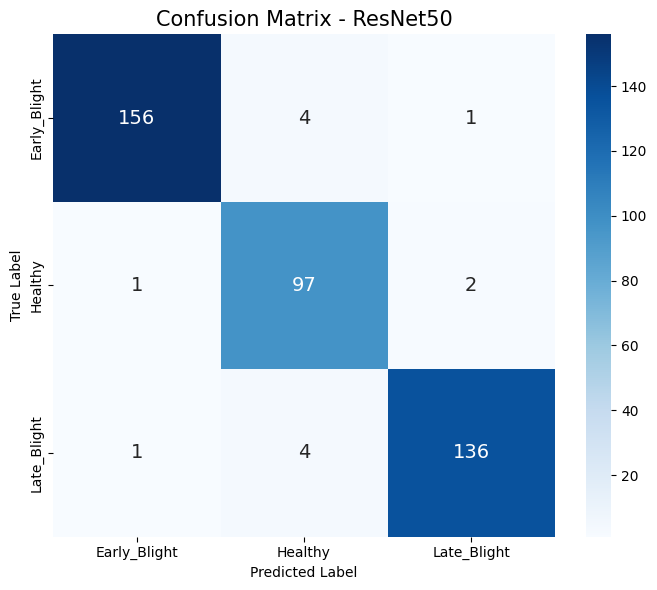

ResNet50 Classification Report:

              precision    recall  f1-score   support

Early_Blight     0.9873    0.9689    0.9781       161
     Healthy     0.9238    0.9700    0.9463       100
 Late_Blight     0.9784    0.9645    0.9714       141

    accuracy                         0.9677       402
   macro avg     0.9632    0.9678    0.9653       402
weighted avg     0.9684    0.9677    0.9678       402



In [53]:
class_names = ["Early_Blight", "Healthy", "Late_Blight"]

# Get predictions
sample_image = None
true_label = None
y_true_resnet = []
y_pred_resnet = []

for images, labels in test_ds:
    probabilities = resnet_model.predict(images, verbose=0)
    y_pred_resnet.extend(np.argmax(probabilities, axis=1))
    y_true_resnet.extend(labels.numpy())

y_true_resnet = np.array(y_true_resnet)
y_pred_resnet = np.array(y_pred_resnet)

# Confusion Matrix
cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 14}
)

plt.title("Confusion Matrix - ResNet50", fontsize=15)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Classification Report
print("ResNet50 Classification Report:\n")
print(
    classification_report(
        y_true_resnet,
        y_pred_resnet,
        target_names=class_names,
        digits=4
    )
)

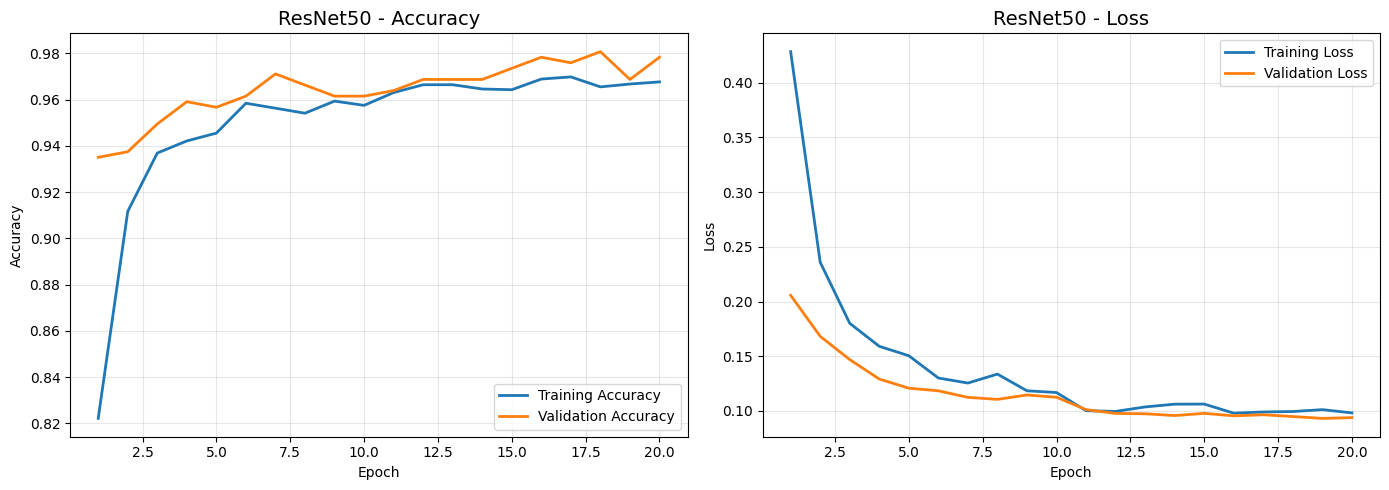

In [54]:
history = resnet_history.history

epochs = range(1, len(history["accuracy"]) + 1)

plt.figure(figsize=(14, 5))

# Accuracy Curve
plt.subplot(1, 2, 1)

plt.plot(
    epochs,
    history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.title("ResNet50 - Accuracy", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)


# Loss Curve
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.title("ResNet50 - Loss", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

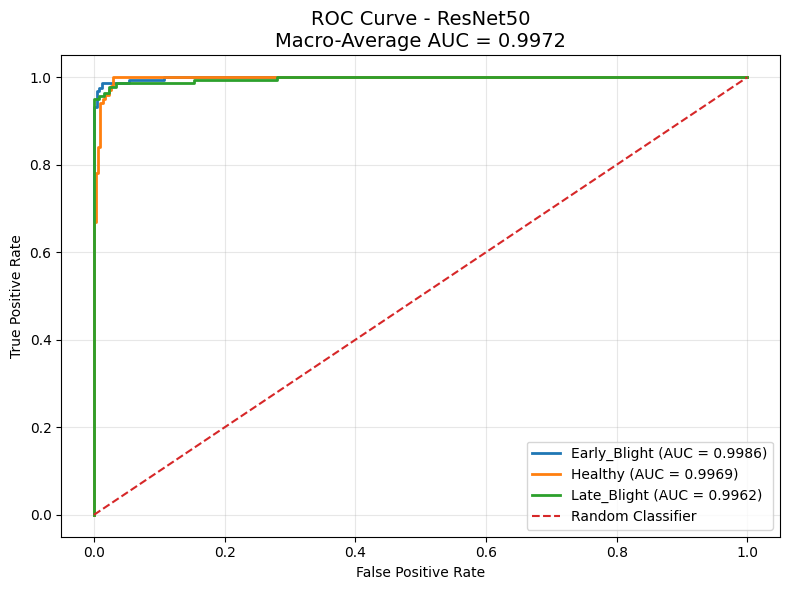

ResNet50 Class-wise AUC:
Early_Blight: 0.9986
Healthy: 0.9969
Late_Blight: 0.9962

ResNet50 Macro-Average AUC: 0.9972


In [55]:

class_names = ["Early_Blight", "Healthy", "Late_Blight"]

# Get true labels and prediction probabilities
y_true_resnet_roc = []
y_prob_resnet = []

for images, labels in test_ds:
    probabilities = resnet_model.predict(images, verbose=0)

    y_prob_resnet.extend(probabilities)
    y_true_resnet_roc.extend(labels.numpy())

y_true_resnet_roc = np.array(y_true_resnet_roc)
y_prob_resnet = np.array(y_prob_resnet)

# One-vs-Rest binary labels
y_true_bin_resnet = label_binarize(
    y_true_resnet_roc,
    classes=[0, 1, 2]
)

# ROC and AUC for each class
fpr_resnet = {}
tpr_resnet = {}
roc_auc_resnet = {}

for i in range(3):
    fpr_resnet[i], tpr_resnet[i], _ = roc_curve(
        y_true_bin_resnet[:, i],
        y_prob_resnet[:, i]
    )

    roc_auc_resnet[i] = auc(
        fpr_resnet[i],
        tpr_resnet[i]
    )

# Macro-average AUC
macro_auc_resnet = roc_auc_score(
    y_true_bin_resnet,
    y_prob_resnet,
    multi_class="ovr",
    average="macro"
)

# Plot
plt.figure(figsize=(8, 6))

for i in range(3):
    plt.plot(
        fpr_resnet[i],
        tpr_resnet[i],
        linewidth=2,
        label=f"{class_names[i]} (AUC = {roc_auc_resnet[i]:.4f})"
    )

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"ROC Curve - ResNet50\nMacro-Average AUC = {macro_auc_resnet:.4f}",
    fontsize=14
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print AUC values
print("ResNet50 Class-wise AUC:")

for i in range(3):
    print(
        f"{class_names[i]}: "
        f"{roc_auc_resnet[i]:.4f}"
    )

print(
    f"\nResNet50 Macro-Average AUC: "
    f"{macro_auc_resnet:.4f}"
)

In [56]:
# MobileNetV2 backbone
mobilenet_base = tf.keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(256, 256, 3)
)

# Freeze pretrained layers
mobilenet_base.trainable = False

# Build MobileNetV2 model
mobilenet_model = models.Sequential([
    layers.Input(shape=(256, 256, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),

    mobilenet_base,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(3, activation="softmax")
])

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

/tmp/ipykernel_1646/2018488218.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet_base = tf.keras.applications.MobileNetV2(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 256, 256, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 8, 8, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [57]:
# Save best MobileNetV2 weights
mobilenet_checkpoint = "/content/mobilenetv2_best.weights.h5"

callbacks = [
    ModelCheckpoint(
        mobilenet_checkpoint,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Train MobileNetV2
mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

# Load best weights
mobilenet_model.load_weights(mobilenet_checkpoint)

# Final test evaluation
mobilenet_test_loss, mobilenet_test_accuracy = mobilenet_model.evaluate(
    test_ds,
    verbose=1
)

print("\nMobileNetV2 Final Test Results")
print(f"Test Loss     : {mobilenet_test_loss:.4f}")
print(f"Test Accuracy : {mobilenet_test_accuracy * 100:.2f}%")

Epoch 1/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.4654 - loss: 1.0889
Epoch 1: val_accuracy improved from None to 0.66346, saving model to /content/mobilenetv2_best.weights.h5

Epoch 1: finished saving model to /content/mobilenetv2_best.weights.h5
102/102 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - accuracy: 0.5503 - loss: 0.9560 - val_accuracy: 0.6635 - val_loss: 0.7484 - learning_rate: 0.0010
Epoch 2/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.6895 - loss: 0.7170
Epoch 2: val_accuracy improved from 0.66346 to 0.75000, saving model to /content/mobilenetv2_best.weights.h5

Epoch 2: finished saving model to /content/mobilenetv2_best.weights.h5
102/102 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.7053 - loss: 0.7020 - val_accuracy: 0.7500 - val_loss: 0.6189 - learning_rate: 0.0010
Epoch 3/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.7441 - loss: 0.6216
Epoch 3: val_accuracy did not improve from 0.75000
102/102 ━━━━━━━━━━━━━━━━━━━━ 10s 91ms/step

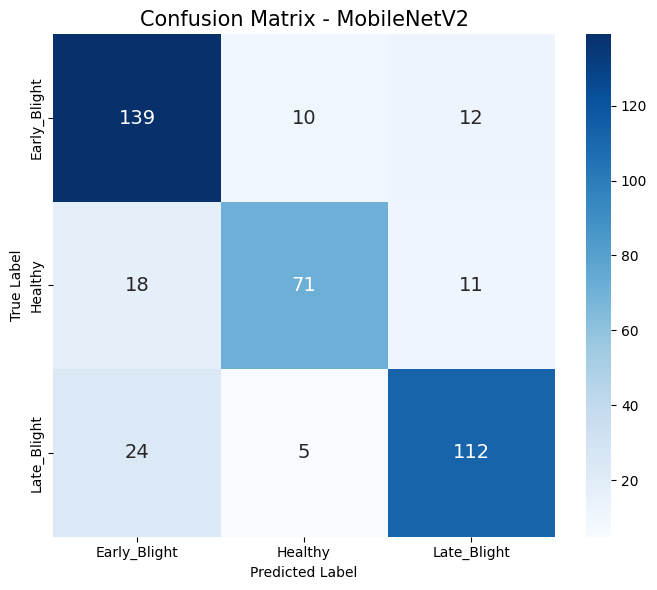

MobileNetV2 Classification Report:

              precision    recall  f1-score   support

Early_Blight     0.7680    0.8634    0.8129       161
     Healthy     0.8256    0.7100    0.7634       100
 Late_Blight     0.8296    0.7943    0.8116       141

    accuracy                         0.8010       402
   macro avg     0.8077    0.7892    0.7960       402
weighted avg     0.8039    0.8010    0.8001       402



In [58]:
class_names = ["Early_Blight", "Healthy", "Late_Blight"]

# Get predictions
y_true_mobilenet = []
y_pred_mobilenet = []

for images, labels in test_ds:
    probabilities = mobilenet_model.predict(images, verbose=0)
    y_pred_mobilenet.extend(np.argmax(probabilities, axis=1))
    y_true_mobilenet.extend(labels.numpy())

y_true_mobilenet = np.array(y_true_mobilenet)
y_pred_mobilenet = np.array(y_pred_mobilenet)

# Confusion Matrix
cm_mobilenet = confusion_matrix(
    y_true_mobilenet,
    y_pred_mobilenet
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_mobilenet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 14}
)

plt.title("Confusion Matrix - MobileNetV2", fontsize=15)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Classification Report
print("MobileNetV2 Classification Report:\n")
print(
    classification_report(
        y_true_mobilenet,
        y_pred_mobilenet,
        target_names=class_names,
        digits=4
    )
)

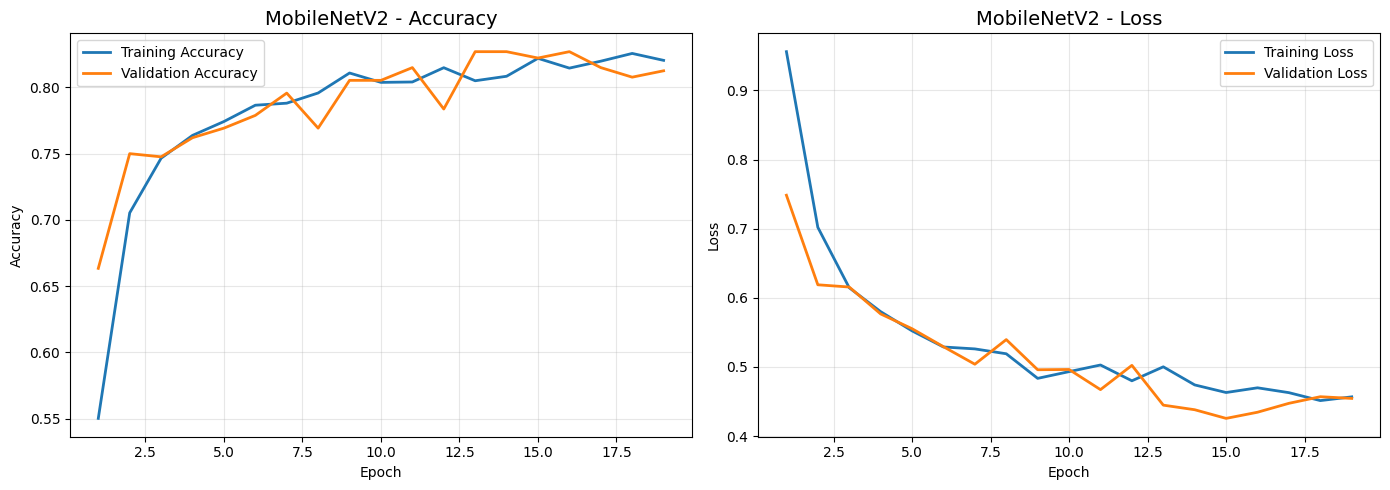

In [59]:
import matplotlib.pyplot as plt

history = mobilenet_history.history

epochs = range(1, len(history["accuracy"]) + 1)

plt.figure(figsize=(14, 5))

# Accuracy Curve
plt.subplot(1, 2, 1)

plt.plot(
    epochs,
    history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.title("MobileNetV2 - Accuracy", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)


# Loss Curve
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.title("MobileNetV2 - Loss", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

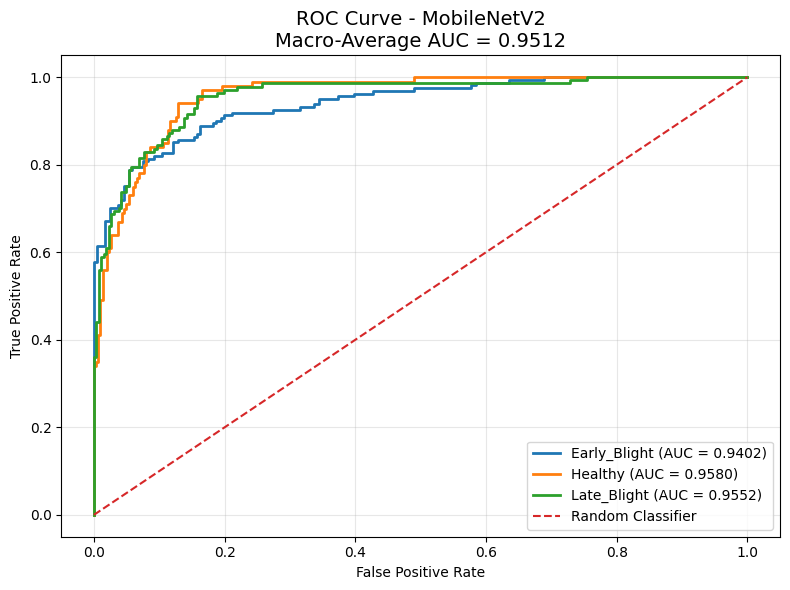

MobileNetV2 Class-wise AUC:
Early_Blight: 0.9402
Healthy: 0.9580
Late_Blight: 0.9552

MobileNetV2 Macro-Average AUC: 0.9512


In [60]:

import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

class_names = ["Early_Blight", "Healthy", "Late_Blight"]

# Get true labels and prediction probabilities
y_true_mobilenet_roc = []
y_prob_mobilenet = []

for images, labels in test_ds:
    probabilities = mobilenet_model.predict(images, verbose=0)

    y_prob_mobilenet.extend(probabilities)
    y_true_mobilenet_roc.extend(labels.numpy())

y_true_mobilenet_roc = np.array(y_true_mobilenet_roc)
y_prob_mobilenet = np.array(y_prob_mobilenet)

# Convert labels to one-vs-rest format
y_true_bin_mobilenet = label_binarize(
    y_true_mobilenet_roc,
    classes=[0, 1, 2]
)

# Calculate ROC and AUC for each class
fpr_mobilenet = {}
tpr_mobilenet = {}
roc_auc_mobilenet = {}

for i in range(3):
    fpr_mobilenet[i], tpr_mobilenet[i], _ = roc_curve(
        y_true_bin_mobilenet[:, i],
        y_prob_mobilenet[:, i]
    )

    roc_auc_mobilenet[i] = auc(
        fpr_mobilenet[i],
        tpr_mobilenet[i]
    )

# Macro-average AUC
macro_auc_mobilenet = roc_auc_score(
    y_true_bin_mobilenet,
    y_prob_mobilenet,
    multi_class="ovr",
    average="macro"
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

for i in range(3):
    plt.plot(
        fpr_mobilenet[i],
        tpr_mobilenet[i],
        linewidth=2,
        label=f"{class_names[i]} (AUC = {roc_auc_mobilenet[i]:.4f})"
    )

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"ROC Curve - MobileNetV2\nMacro-Average AUC = {macro_auc_mobilenet:.4f}",
    fontsize=14
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print AUC values
print("MobileNetV2 Class-wise AUC:")

for i in range(3):
    print(
        f"{class_names[i]}: "
        f"{roc_auc_mobilenet[i]:.4f}"
    )

print(
    f"\nMobileNetV2 Macro-Average AUC: "
    f"{macro_auc_mobilenet:.4f}"
)

In [61]:
import tensorflow as tf
from tensorflow.keras import layers, models

# EfficientNetB0 backbone
efficientnet_base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(256, 256, 3)
)

# Freeze pretrained layers
efficientnet_base.trainable = False

# Build EfficientNetB0 model
efficientnet_model = models.Sequential([
    layers.Input(shape=(256, 256, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),

    efficientnet_base,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(3, activation="softmax")
])

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_2               │ (None, 256, 256, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [62]:
# Save best EfficientNetB0 weights
efficientnet_checkpoint = "/content/efficientnetb0_best.weights.h5"

callbacks = [
    ModelCheckpoint(
        efficientnet_checkpoint,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Train EfficientNetB0
efficientnet_history = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

# Load best weights
efficientnet_model.load_weights(efficientnet_checkpoint)

# Final test evaluation
efficientnet_test_loss, efficientnet_test_accuracy = efficientnet_model.evaluate(
    test_ds,
    verbose=1
)

print("\nEfficientNetB0 Final Test Results")
print(f"Test Loss     : {efficientnet_test_loss:.4f}")

Epoch 1/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.6965 - loss: 0.7397
Epoch 1: val_accuracy improved from None to 0.92067, saving model to /content/efficientnetb0_best.weights.h5

Epoch 1: finished saving model to /content/efficientnetb0_best.weights.h5
102/102 ━━━━━━━━━━━━━━━━━━━━ 26s 153ms/step - accuracy: 0.8081 - loss: 0.5246 - val_accuracy: 0.9207 - val_loss: 0.2837 - learning_rate: 0.0010
Epoch 2/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.9222 - loss: 0.2571
Epoch 2: val_accuracy improved from 0.92067 to 0.93510, saving model to /content/efficientnetb0_best.weights.h5

Epoch 2: finished saving model to /content/efficientnetb0_best.weights.h5
102/102 ━━━━━━━━━━━━━━━━━━━━ 13s 131ms/step - accuracy: 0.9299 - loss: 0.2430 - val_accuracy: 0.9351 - val_loss: 0.2040 - learning_rate: 0.0010
Epoch 3/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.9310 - loss: 0.2066
Epoch 3: val_accuracy improved from 0.93510 to 0.95192, saving model to /cont

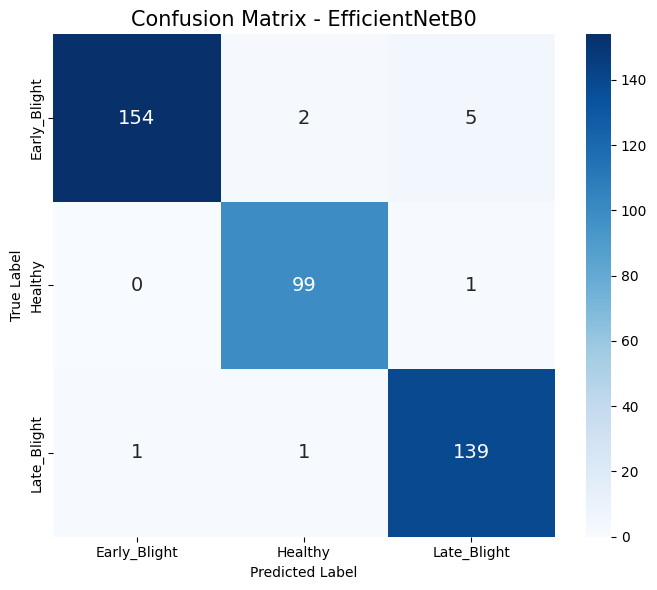

EfficientNetB0 Classification Report:

              precision    recall  f1-score   support

Early_Blight     0.9935    0.9565    0.9747       161
     Healthy     0.9706    0.9900    0.9802       100
 Late_Blight     0.9586    0.9858    0.9720       141

    accuracy                         0.9751       402
   macro avg     0.9743    0.9774    0.9756       402
weighted avg     0.9756    0.9751    0.9751       402



In [63]:
from sklearn.metrics import confusion_matrix, classification_report

class_names = ["Early_Blight", "Healthy", "Late_Blight"]

# Get predictions
y_true_efficientnet = []
y_pred_efficientnet = []

for images, labels in test_ds:
    probabilities = efficientnet_model.predict(images, verbose=0)

    y_pred_efficientnet.extend(np.argmax(probabilities, axis=1))
    y_true_efficientnet.extend(labels.numpy())

y_true_efficientnet = np.array(y_true_efficientnet)
y_pred_efficientnet = np.array(y_pred_efficientnet)

# Confusion Matrix
cm_efficientnet = confusion_matrix(
    y_true_efficientnet,
    y_pred_efficientnet
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_efficientnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 14}
)

plt.title("Confusion Matrix - EfficientNetB0", fontsize=15)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Classification Report
print("EfficientNetB0 Classification Report:\n")

print(
    classification_report(
        y_true_efficientnet,
        y_pred_efficientnet,
        target_names=class_names,
        digits=4
    )
)

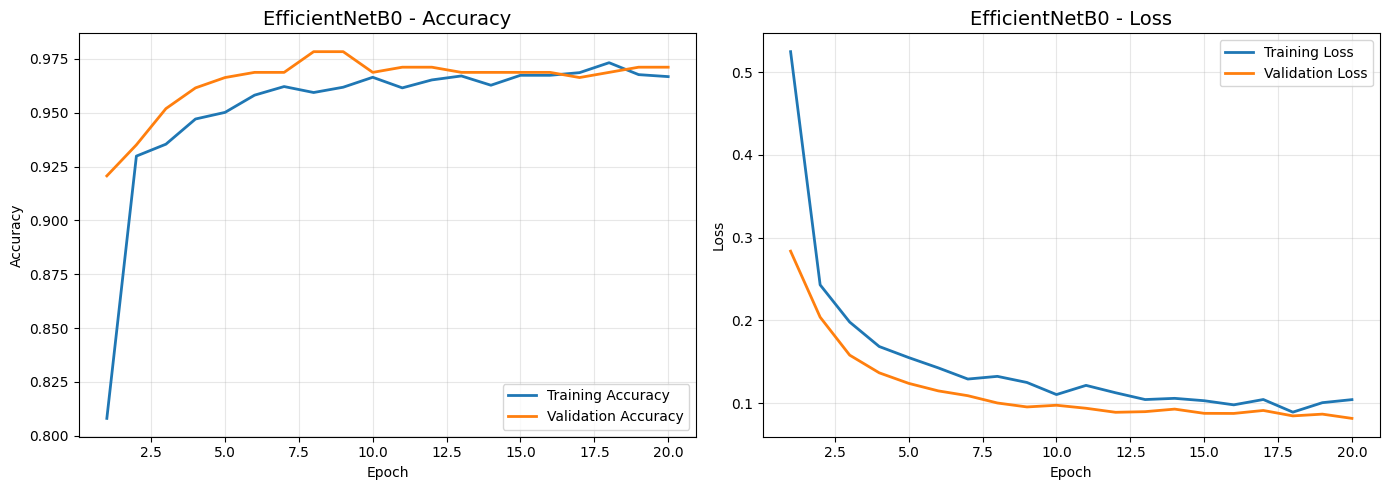

In [64]:
import matplotlib.pyplot as plt

history = efficientnet_history.history

epochs = range(1, len(history["accuracy"]) + 1)

plt.figure(figsize=(14, 5))

# Accuracy Curve
plt.subplot(1, 2, 1)

plt.plot(
    epochs,
    history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.title("EfficientNetB0 - Accuracy", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)


# Loss Curve
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.title("EfficientNetB0 - Loss", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

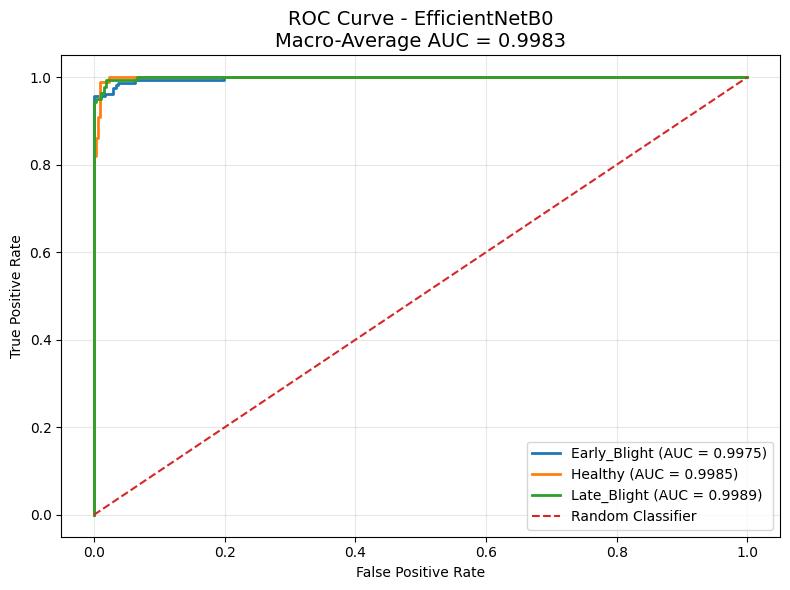

EfficientNetB0 Class-wise AUC:
Early_Blight: 0.9975
Healthy: 0.9985
Late_Blight: 0.9989

EfficientNetB0 Macro-Average AUC: 0.9983


In [65]:


class_names = ["Early_Blight", "Healthy", "Late_Blight"]

# Get true labels and prediction probabilities
y_true_efficientnet_roc = []
y_prob_efficientnet = []

for images, labels in test_ds:
    probabilities = efficientnet_model.predict(images, verbose=0)

    y_prob_efficientnet.extend(probabilities)
    y_true_efficientnet_roc.extend(labels.numpy())

y_true_efficientnet_roc = np.array(y_true_efficientnet_roc)
y_prob_efficientnet = np.array(y_prob_efficientnet)

# Convert labels to one-vs-rest format
y_true_bin_efficientnet = label_binarize(
    y_true_efficientnet_roc,
    classes=[0, 1, 2]
)

# Calculate ROC and AUC for each class
fpr_efficientnet = {}
tpr_efficientnet = {}
roc_auc_efficientnet = {}

for i in range(3):
    fpr_efficientnet[i], tpr_efficientnet[i], _ = roc_curve(
        y_true_bin_efficientnet[:, i],
        y_prob_efficientnet[:, i]
    )

    roc_auc_efficientnet[i] = auc(
        fpr_efficientnet[i],
        tpr_efficientnet[i]
    )

# Macro-average AUC
macro_auc_efficientnet = roc_auc_score(
    y_true_bin_efficientnet,
    y_prob_efficientnet,
    multi_class="ovr",
    average="macro"
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

for i in range(3):
    plt.plot(
        fpr_efficientnet[i],
        tpr_efficientnet[i],
        linewidth=2,
        label=f"{class_names[i]} (AUC = {roc_auc_efficientnet[i]:.4f})"
    )

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"ROC Curve - EfficientNetB0\nMacro-Average AUC = {macro_auc_efficientnet:.4f}",
    fontsize=14
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print AUC values
print("EfficientNetB0 Class-wise AUC:")

for i in range(3):
    print(
        f"{class_names[i]}: "
        f"{roc_auc_efficientnet[i]:.4f}"
    )

print(
    f"\nEfficientNetB0 Macro-Average AUC: "
    f"{macro_auc_efficientnet:.4f}"
)

In [66]:
comparison = pd.DataFrame({
    "Model": [
        "Improved Custom CNN",
        "ResNet50",
        "MobileNetV2",
        "EfficientNetB0"
    ],

    "Test Accuracy (%)": [
        improved_test_accuracy * 100,
        resnet_test_accuracy * 100,
        mobilenet_test_accuracy * 100,
        efficientnet_test_accuracy * 100
    ],

    "Test Loss": [
        improved_test_loss,
        resnet_test_loss,
        mobilenet_test_loss,
        efficientnet_test_loss
    ]
})

comparison = comparison.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print("Final Model Comparison")
display(comparison.round(4))

Final Model Comparison


,Model,Test Accuracy (%),Test Loss
0,EfficientNetB0,97.5124,0.1016
1,ResNet50,96.7662,0.1015
2,Improved Custom CNN,94.2786,0.1566
3,MobileNetV2,80.0995,0.4544


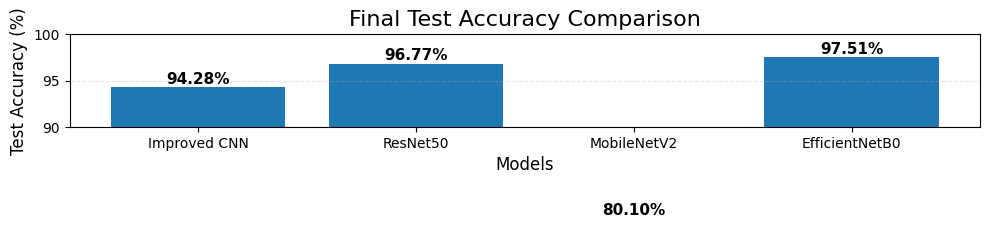

In [67]:
models = [
    "Improved CNN",
    "ResNet50",
    "MobileNetV2",
    "EfficientNetB0"
]

accuracies = [
    improved_test_accuracy * 100,
    resnet_test_accuracy * 100,
    mobilenet_test_accuracy * 100,
    efficientnet_test_accuracy * 100
]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, accuracies)

plt.title(
    "Final Test Accuracy Comparison",
    fontsize=16
)

plt.xlabel("Models", fontsize=12)
plt.ylabel("Test Accuracy (%)", fontsize=12)

plt.ylim(90, 100)

# Accuracy labels
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

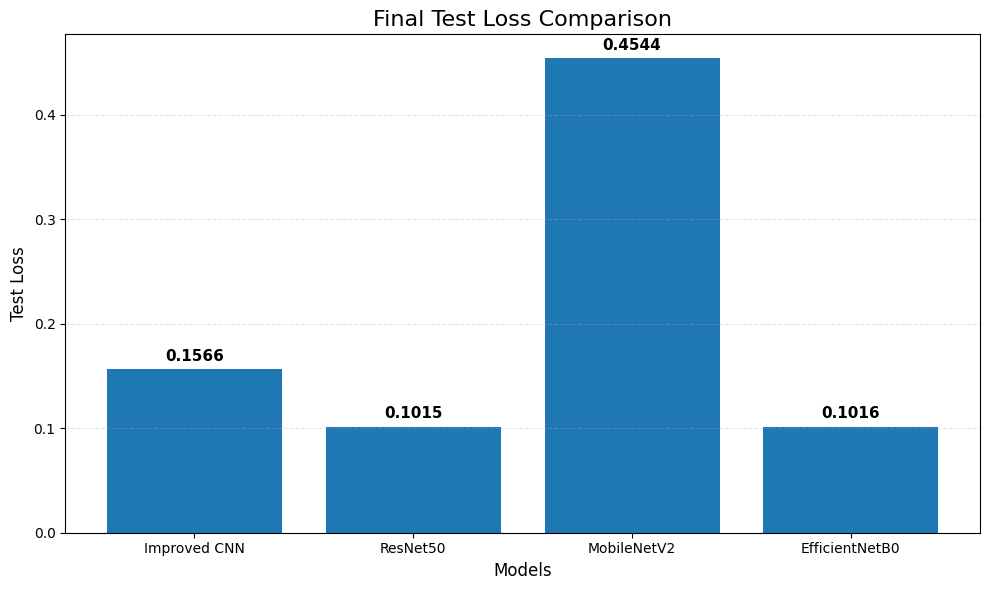

In [68]:
import matplotlib.pyplot as plt

models = [
    "Improved CNN",
    "ResNet50",
    "MobileNetV2",
    "EfficientNetB0"
]

losses = [
    improved_test_loss,
    resnet_test_loss,
    mobilenet_test_loss,
    efficientnet_test_loss
]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, losses)

plt.title(
    "Final Test Loss Comparison",
    fontsize=16
)

plt.xlabel("Models", fontsize=12)
plt.ylabel("Test Loss", fontsize=12)

# Loss labels
for bar, loss in zip(bars, losses):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{loss:.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [69]:
# Find all convolutional layers in the Improved Custom CNN

for layer in improved_cnn.layers:
    if isinstance(layer, tf.keras.layers.Conv2D):
        print(layer.name, layer.output.shape)

conv2d_15 (None, 256, 256, 32)
conv2d_16 (None, 256, 256, 32)
conv2d_17 (None, 128, 128, 64)
conv2d_18 (None, 128, 128, 64)
conv2d_19 (None, 64, 64, 128)
conv2d_20 (None, 64, 64, 128)
conv2d_21 (None, 32, 32, 256)


In [70]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Write the last Conv2D layer name here
LAST_CONV_LAYER = "conv2d_9"

# Grad-CAM function
def make_gradcam(model, image, last_conv_layer_name, pred_index=None):

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(image)

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_channel = predictions[:, pred_index]

    # Gradient of predicted class
    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap /= max_value

    return heatmap.numpy(), int(pred_index)


# Take one image from test dataset
for images, labels in test_ds.take(1):

    sample_image = images[0:1]
    true_label = int(labels[0])

    heatmap, predicted_class = make_gradcam(
        improved_cnn,
        sample_image,
        LAST_CONV_LAYER
    )

    break


# Display
plt.figure(figsize=(7, 6))

plt.imshow(sample_image[0].numpy().astype("uint8"))
plt.imshow(
    heatmap,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"Grad-CAM - Improved Custom CNN\n"
    f"True: {class_names[true_label]} | "
    f"Predicted: {class_names[predicted_class]}",
    fontsize=13
)

plt.axis("off")
plt.tight_layout()
plt.show()

ValueError: No such layer: conv2d_9. Existing layers are: ['input_layer_5', 'data_augmentation', 'conv2d_15', 'batch_normalization_3', 'activation_3', 'conv2d_16', 'batch_normalization_4', 'activation_4', 'max_pooling2d_15', 'dropout_8', 'conv2d_17', 'batch_normalization_5', 'activation_5', 'conv2d_18', 'batch_normalization_6', 'activation_6', 'max_pooling2d_16', 'dropout_9', 'conv2d_19', 'batch_normalization_7', 'activation_7', 'conv2d_20', 'batch_normalization_8', 'activation_8', 'max_pooling2d_17', 'dropout_10', 'conv2d_21', 'batch_normalization_9', 'activation_9', 'global_average_pooling2d_1', 'dense_9', 'dropout_11', 'dense_10'].

## Attention-Enhanced Custom CNN (Residual Connections + CBAM)

Run this section **after** the existing dataset and preprocessing cells. It uses `train_improved`, `val_improved`, `test_final`, `data_augmentation`, and `CLASS_NAMES` already defined in this notebook. This adds a new experiment; it does not overwrite the existing model results.


In [ ]:
# Attention-enhanced Custom CNN: Residual blocks + CBAM attention
# IMPORTANT: use tf.keras.Model, not models.Model. In an earlier cell, `models`
# is reassigned to a Python list for plotting, which causes: list has no attribute Model.

import tensorflow as tf
from tensorflow.keras import layers, regularizers

# Reuse the notebook's existing data_augmentation layer and dataset variables.

def cbam_attention(x, reduction_ratio=8, name="cbam"):
    """CBAM: channel attention followed by spatial attention."""
    channels = int(x.shape[-1])

    # Channel attention: share the same MLP between average- and max-pooled features.
    shared_dense_1 = layers.Dense(
        max(channels // reduction_ratio, 8), activation="relu",
        kernel_initializer="he_normal", use_bias=True,
        name=f"{name}_channel_mlp_1"
    )
    shared_dense_2 = layers.Dense(
        channels, kernel_initializer="he_normal", use_bias=True,
        name=f"{name}_channel_mlp_2"
    )

    avg_pool = layers.GlobalAveragePooling2D(name=f"{name}_avg_pool")(x)
    max_pool = layers.GlobalMaxPooling2D(name=f"{name}_max_pool")(x)
    avg_out = shared_dense_2(shared_dense_1(avg_pool))
    max_out = shared_dense_2(shared_dense_1(max_pool))
    channel_weights = layers.Add(name=f"{name}_channel_add")([avg_out, max_out])
    channel_weights = layers.Activation("sigmoid", name=f"{name}_channel_sigmoid")(channel_weights)
    channel_weights = layers.Reshape((1, 1, channels), name=f"{name}_channel_reshape")(channel_weights)
    x = layers.Multiply(name=f"{name}_channel_refine")([x, channel_weights])

    # Spatial attention: channel-wise average and maximum maps.
    avg_spatial = layers.Lambda(
        lambda t: tf.reduce_mean(t, axis=-1, keepdims=True),
        name=f"{name}_spatial_avg"
    )(x)
    max_spatial = layers.Lambda(
        lambda t: tf.reduce_max(t, axis=-1, keepdims=True),
        name=f"{name}_spatial_max"
    )(x)
    spatial = layers.Concatenate(axis=-1, name=f"{name}_spatial_concat")(
        [avg_spatial, max_spatial]
    )
    spatial_weights = layers.Conv2D(
        1, kernel_size=7, padding="same", activation="sigmoid",
        use_bias=False, name=f"{name}_spatial_conv"
    )(spatial)
    return layers.Multiply(name=f"{name}_spatial_refine")([x, spatial_weights])


def residual_cbam_block(x, filters, dropout_rate, name):
    shortcut = x
    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)

    # Match shortcut channels before adding the residual path.
    if int(shortcut.shape[-1]) != filters:
        shortcut = layers.Conv2D(
            filters, 1, padding="same", use_bias=False,
            name=f"{name}_projection"
        )(shortcut)
        shortcut = layers.BatchNormalization(name=f"{name}_projection_bn")(shortcut)

    x = layers.Add(name=f"{name}_residual_add")([x, shortcut])
    x = layers.Activation("relu", name=f"{name}_residual_relu")(x)
    x = cbam_attention(x, name=f"{name}_cbam")
    x = layers.MaxPooling2D(2, name=f"{name}_pool")(x)
    x = layers.Dropout(dropout_rate, name=f"{name}_dropout")(x)
    return x


def build_attention_residual_cnn():
    inputs = layers.Input(shape=(256, 256, 3), name="image_input")
    x = data_augmentation(inputs)
    x = residual_cbam_block(x, 32, 0.15, "block1")
    x = residual_cbam_block(x, 64, 0.20, "block2")
    x = residual_cbam_block(x, 128, 0.25, "block3")

    x = layers.Conv2D(
        256, 3, padding="same", use_bias=False, name="block4_conv"
    )(x)
    x = layers.BatchNormalization(name="block4_bn")(x)
    x = layers.Activation("relu", name="block4_relu")(x)
    x = cbam_attention(x, name="block4_cbam")

    x = layers.GlobalAveragePooling2D(name="global_average_pool")(x)
    x = layers.Dense(
        128, activation="relu", kernel_regularizer=regularizers.l2(1e-4),
        name="classifier_dense"
    )(x)
    x = layers.Dropout(0.35, name="classifier_dropout")(x)
    outputs = layers.Dense(3, activation="softmax", name="class_output")(x)

    # Use tf.keras.Model so this works even if `models` was overwritten elsewhere.
    return tf.keras.Model(inputs, outputs, name="Residual_CBAM_Custom_CNN")

attention_cnn = build_attention_residual_cnn()
attention_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
attention_cnn.summary()


In [ ]:
# Train the new attention-enhanced model
# Uses the existing train_improved and val_improved datasets.

attention_checkpoint = "/content/residual_cbam_custom_cnn_best.weights.h5"
attention_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        attention_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

attention_cnn_history = attention_cnn.fit(
    train_improved,
    validation_data=val_improved,
    epochs=20,
    callbacks=attention_callbacks,
    verbose=1
)

print("Best validation accuracy:", round(max(attention_cnn_history.history["val_accuracy"]) * 100, 4), "%")
print("Best validation loss:", round(min(attention_cnn_history.history["val_loss"]), 4))


In [ ]:
# Evaluate Attention-Enhanced Custom CNN on the held-out test set
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize

attention_test_loss, attention_test_accuracy = attention_cnn.evaluate(test_final, verbose=1)
print(f"Attention-Enhanced CNN Test Accuracy: {attention_test_accuracy * 100:.4f}%")
print(f"Attention-Enhanced CNN Test Loss: {attention_test_loss:.4f}")

attention_y_true = []
attention_y_prob = []
for images, labels in test_final:
    probs = attention_cnn.predict(images, verbose=0)
    attention_y_prob.extend(probs)
    attention_y_true.extend(labels.numpy())

attention_y_true = np.asarray(attention_y_true)
attention_y_prob = np.asarray(attention_y_prob)
attention_y_pred = np.argmax(attention_y_prob, axis=1)

print("\nClassification Report")
print(classification_report(
    attention_y_true, attention_y_pred,
    target_names=CLASS_NAMES, digits=4, zero_division=0
))

attention_cm = confusion_matrix(attention_y_true, attention_y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(
    attention_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.title("Confusion Matrix - Residual CBAM Custom CNN")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

attention_y_true_bin = label_binarize(attention_y_true, classes=np.arange(len(CLASS_NAMES)))
attention_macro_auc = roc_auc_score(
    attention_y_true_bin, attention_y_prob,
    average="macro", multi_class="ovr"
)
print(f"Macro-average ROC-AUC: {attention_macro_auc:.4f}")

# Compare to the existing models only if their test metrics are already defined.
attention_comparison_rows = [{
    "Model": "Residual + CBAM Custom CNN",
    "Test Accuracy (%)": attention_test_accuracy * 100,
    "Test Loss": attention_test_loss,
    "Macro-Average AUC": attention_macro_auc
}]
if "improved_test_accuracy" in globals() and "improved_test_loss" in globals():
    attention_comparison_rows.append({
        "Model": "Improved Custom CNN",
        "Test Accuracy (%)": improved_test_accuracy * 100,
        "Test Loss": improved_test_loss,
        "Macro-Average AUC": np.nan
    })
if "resnet_test_accuracy" in globals() and "resnet_test_loss" in globals():
    attention_comparison_rows.append({
        "Model": "ResNet50",
        "Test Accuracy (%)": resnet_test_accuracy * 100,
        "Test Loss": resnet_test_loss,
        "Macro-Average AUC": np.nan
    })
if "mobilenet_test_accuracy" in globals() and "mobilenet_test_loss" in globals():
    attention_comparison_rows.append({
        "Model": "MobileNetV2",
        "Test Accuracy (%)": mobilenet_test_accuracy * 100,
        "Test Loss": mobilenet_test_loss,
        "Macro-Average AUC": np.nan
    })
if "efficientnet_test_accuracy" in globals() and "efficientnet_test_loss" in globals():
    attention_comparison_rows.append({
        "Model": "EfficientNetB0",
        "Test Accuracy (%)": efficientnet_test_accuracy * 100,
        "Test Loss": efficientnet_test_loss,
        "Macro-Average AUC": np.nan
    })

attention_comparison = pd.DataFrame(attention_comparison_rows).sort_values(
    "Test Accuracy (%)", ascending=False
).reset_index(drop=True)
print("\nModel comparison (AUC shown only where calculated in this section):")
display(attention_comparison.round(4))


# Additional Required Evaluation (Paper-Ready)

Run these cells **after Cell 84**, where the Residual + CBAM model has already been trained and evaluated. These cells use the notebook's existing variables and class order.


In [ ]:
# CELL A: Training and validation curves for the proposed Residual + CBAM model
import matplotlib.pyplot as plt

att_hist = attention_cnn_history.history
epochs = range(1, len(att_hist["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs, att_hist["accuracy"], marker="o", label="Training Accuracy")
axes[0].plot(epochs, att_hist["val_accuracy"], marker="o", label="Validation Accuracy")
axes[0].set_title("Residual + CBAM: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, att_hist["loss"], marker="o", label="Training Loss")
axes[1].plot(epochs, att_hist["val_loss"], marker="o", label="Validation Loss")
axes[1].set_title("Residual + CBAM: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/content/residual_cbam_training_validation_curves.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# CELL B: One consistent comparison table for ALL trained models
# Macro-F1 is calculated from the same held-out test set for every model.
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

models_for_comparison = [
    ("Baseline Custom CNN", baseline_cnn, baseline_test_loss, baseline_test_accuracy),
    ("Improved Custom CNN", improved_cnn, improved_test_loss, improved_test_accuracy),
    ("ResNet50", resnet_model, resnet_test_loss, resnet_test_accuracy),
    ("MobileNetV2", mobilenet_model, mobilenet_test_loss, mobilenet_test_accuracy),
    ("EfficientNetB0", efficientnet_model, efficientnet_test_loss, efficientnet_test_accuracy),
    ("Residual + CBAM Custom CNN", attention_cnn, attention_test_loss, attention_test_accuracy),
]

comparison_rows = []
for model_name, model_obj, test_loss_value, test_acc_value in models_for_comparison:
    true_labels, predicted_labels = [], []
    for batch_images, batch_labels in test_final:  # test_final has shuffle=False
        batch_probs = model_obj.predict(batch_images, verbose=0)
        true_labels.extend(batch_labels.numpy().tolist())
        predicted_labels.extend(np.argmax(batch_probs, axis=1).tolist())

    macro_f1_value = f1_score(true_labels, predicted_labels, average="macro", zero_division=0)
    comparison_rows.append({
        "Model": model_name,
        "Test Accuracy (%)": test_acc_value * 100,
        "Test Loss": test_loss_value,
        "Macro F1-score": macro_f1_value
    })

final_model_comparison = pd.DataFrame(comparison_rows).sort_values(
    by="Test Accuracy (%)", ascending=False
).reset_index(drop=True)

print("FINAL MODEL COMPARISON (same held-out test set)")
display(final_model_comparison.round(4))
final_model_comparison.to_csv("/content/final_model_comparison.csv", index=False)


In [ ]:
# CELL C: Detailed evaluation of the proposed Residual + CBAM model
# Confusion matrix + per-class Precision, Recall, F1-score + Macro/Weighted averages
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Reuse predictions already created in Cell 84.
attention_cm = confusion_matrix(attention_y_true, attention_y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    attention_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 13}
)
plt.title("Confusion Matrix - Residual + CBAM")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig("/content/residual_cbam_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Classification Report - Residual + CBAM")
print(classification_report(
    attention_y_true, attention_y_pred,
    target_names=CLASS_NAMES, digits=4, zero_division=0
))


In [ ]:
# CELL D: Grad-CAM explainability for Residual + CBAM
# The final convolutional feature map in this architecture is named 'block4_conv'.
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

def make_gradcam_heatmap(model, image_batch, last_conv_layer_name="block4_conv", class_index=None):
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_features, predictions = grad_model(image_batch, training=False)
        if class_index is None:
            class_index = tf.argmax(predictions[0])
        target_score = predictions[:, class_index]

    gradients = tape.gradient(target_score, conv_features)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))
    conv_features = conv_features[0]
    heatmap = tf.reduce_sum(conv_features * pooled_gradients, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    max_heat = tf.reduce_max(heatmap)
    heatmap = tf.math.divide_no_nan(heatmap, max_heat)
    return heatmap.numpy(), int(class_index.numpy()), predictions[0].numpy()

# Show up to 3 test examples. test_final is unshuffled.
shown = 0
for batch_images, batch_labels in test_final:
    for j in range(batch_images.shape[0]):
        image_batch = batch_images[j:j+1]
        true_class = int(batch_labels[j].numpy())
        heatmap, predicted_class, probabilities = make_gradcam_heatmap(
            attention_cnn, image_batch, last_conv_layer_name="block4_conv"
        )

        original = image_batch[0].numpy().astype("uint8")
        heatmap_resized = tf.image.resize(
            heatmap[..., np.newaxis], (original.shape[0], original.shape[1])
        ).numpy().squeeze()

        fig, axes = plt.subplots(1, 3, figsize=(13, 4))
        axes[0].imshow(original)
        axes[0].set_title("Input Image")
        axes[1].imshow(heatmap_resized, cmap="jet")
        axes[1].set_title("Grad-CAM Heatmap")
        axes[2].imshow(original)
        axes[2].imshow(heatmap_resized, cmap="jet", alpha=0.40)
        axes[2].set_title("Grad-CAM Overlay")
        for ax in axes:
            ax.axis("off")
        fig.suptitle(
            f"True: {CLASS_NAMES[true_class]} | Predicted: {CLASS_NAMES[predicted_class]} "
            f"| Confidence: {probabilities[predicted_class]:.3f}"
        )
        plt.tight_layout()
        plt.savefig(f"/content/gradcam_example_{shown+1}.png", dpi=300, bbox_inches="tight")
        plt.show()
        shown += 1
        if shown >= 3:
            break
    if shown >= 3:
        break


## Ablation Study: Residual CNN vs Residual + CBAM

This section trains a Residual-only model with the same block widths, dropout rates, dataset split, input size, optimizer, learning rate, and epoch limit as the Residual + CBAM model. The only intended architectural difference is that CBAM attention is removed. Run this training cell to obtain a valid ablation result; do not invent or reuse an untrained model's metrics.


In [ ]:
# CELL E: Build and train Residual-only CNN (CBAM removed)
import tensorflow as tf
from tensorflow.keras import layers

def residual_only_block(x, filters, dropout_rate, name):
    shortcut = x
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      kernel_initializer="he_normal", name=f"{name}_conv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      kernel_initializer="he_normal", name=f"{name}_conv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)

    if int(shortcut.shape[-1]) != filters:
        shortcut = layers.Conv2D(filters, 1, padding="same", use_bias=False,
                                 name=f"{name}_projection")(shortcut)
        shortcut = layers.BatchNormalization(name=f"{name}_projection_bn")(shortcut)

    x = layers.Add(name=f"{name}_residual_add")([x, shortcut])
    x = layers.Activation("relu", name=f"{name}_residual_relu")(x)
    # No CBAM module in this ablation model.
    x = layers.MaxPooling2D(2, name=f"{name}_pool")(x)
    x = layers.Dropout(dropout_rate, name=f"{name}_dropout")(x)
    return x

def build_residual_only_cnn():
    inputs = layers.Input(shape=(256, 256, 3), name="image_input")
    x = data_augmentation(inputs)
    x = residual_only_block(x, 32, 0.15, "block1")
    x = residual_only_block(x, 64, 0.20, "block2")
    x = residual_only_block(x, 128, 0.25, "block3")
    x = layers.Conv2D(256, 3, padding="same", use_bias=False, name="block4_conv")(x)
    x = layers.BatchNormalization(name="block4_bn")(x)
    x = layers.Activation("relu", name="block4_relu")(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pool")(x)
    x = layers.Dense(128, activation="relu",
                     kernel_regularizer=tf.keras.regularizers.l2(1e-4),
                     name="classifier_dense")(x)
    x = layers.Dropout(0.35, name="classifier_dropout")(x)
    outputs = layers.Dense(3, activation="softmax", name="class_output")(x)
    return tf.keras.Model(inputs, outputs, name="Residual_Only_Custom_CNN")

residual_only_cnn = build_residual_only_cnn()
residual_only_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
residual_only_cnn.summary()

residual_only_checkpoint = "/content/residual_only_custom_cnn_best.weights.h5"
residual_only_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        residual_only_checkpoint, monitor="val_accuracy", mode="max",
        save_best_only=True, save_weights_only=True, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.2, patience=3, min_lr=1e-6, verbose=1
    )
]

residual_only_history = residual_only_cnn.fit(
    train_improved, validation_data=val_improved, epochs=20,
    callbacks=residual_only_callbacks, verbose=1
)
residual_only_cnn.load_weights(residual_only_checkpoint)
residual_only_test_loss, residual_only_test_accuracy = residual_only_cnn.evaluate(
    test_final, verbose=1
)
print(f"Residual-only Test Accuracy: {residual_only_test_accuracy*100:.4f}%")
print(f"Residual-only Test Loss: {residual_only_test_loss:.4f}")


In [ ]:
# CELL F: Ablation results table (same held-out test set)
from sklearn.metrics import f1_score

def get_macro_f1(model_obj, dataset):
    labels_all, preds_all = [], []
    for images, labels in dataset:
        probs = model_obj.predict(images, verbose=0)
        labels_all.extend(labels.numpy().tolist())
        preds_all.extend(np.argmax(probs, axis=1).tolist())
    return f1_score(labels_all, preds_all, average="macro", zero_division=0)

residual_only_macro_f1 = get_macro_f1(residual_only_cnn, test_final)
residual_cbam_macro_f1 = get_macro_f1(attention_cnn, test_final)

ablation_results = pd.DataFrame([
    {
        "Architecture": "Residual CNN (without CBAM)",
        "Test Accuracy (%)": residual_only_test_accuracy * 100,
        "Test Loss": residual_only_test_loss,
        "Macro F1-score": residual_only_macro_f1
    },
    {
        "Architecture": "Residual CNN + CBAM",
        "Test Accuracy (%)": attention_test_accuracy * 100,
        "Test Loss": attention_test_loss,
        "Macro F1-score": residual_cbam_macro_f1
    }
])

print("ABLATION STUDY: Effect of CBAM Attention")
display(ablation_results.round(4))
ablation_results.to_csv("/content/residual_cbam_ablation_results.csv", index=False)
